# <U>Etapa 1</U>: carga e inspeccion general

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Biblitecas importadas correctamente")

Biblitecas importadas correctamente


In [3]:
df = pd.read_csv("../Datos/raw/catalogo_carreras_jujuy_sin_depurar.csv")

In [4]:
df.head(10)

,Carrera,Categoria,Localidad,Institucion,Archivo_origen
0,Profesorado de Educación Tecnológica,Tecnologia,Abra Pampa,Instituto de Educación Superior N° 1,tecnologia_jujuy.csv
1,Tecnicatura superior en ciencia de datos e int...,Tecnologia,Abra Pampa,Instituto de Educación Superior N° 1,tecnologia_jujuy.csv
2,Profesorado de Educación Secundaria en Informá...,Tecnologia,Humahuaca,Instituto de Educación Superior N° 2,tecnologia_jujuy.csv
3,Tecnicatura superior en desarrollo de software,Tecnologia,Humahuaca,Instituto de Educación Superior N° 2,tecnologia_jujuy.csv
4,Tecnicatura superior en mantenimiento industrial,Tecnologia,Maimara,Instituto de Educación Superior N° 2,tecnologia_jujuy.csv
5,Tecnicatura superior en mantenimiento industrial,Tecnologia,Susques,Instituto de Educación Superior N° 3,tecnologia_jujuy.csv
6,Profesorado de Educación Secundaria en Tecnolo...,Tecnologia,San Salvador de Jujuy,Instituto de Educación Superior N° 5,tecnologia_jujuy.csv
7,Profesorado de Educación Tecnológica,Tecnologia,San Salvador de Jujuy,Instituto de Educación Superior N° 5,tecnologia_jujuy.csv
8,Tecnicatura superior en soporte de infraestruc...,Tecnologia,San Salvador de Jujuy,Instituto de Educación Superior N° 5,tecnologia_jujuy.csv
9,Profesorado de Educación Secundaria en Informá...,Tecnologia,Perico,Instituto de Educación Superior N° 6,tecnologia_jujuy.csv


In [5]:
print("Cantidad de filas y columnas:")
df.shape

Cantidad de filas y columnas:


(465, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 465 entries, 0 to 464
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Carrera         465 non-null    object
 1   Categoria       465 non-null    object
 2   Localidad       465 non-null    object
 3   Institucion     465 non-null    object
 4   Archivo_origen  465 non-null    object
dtypes: object(5)
memory usage: 18.3+ KB


In [7]:
df.describe()

,Carrera,Categoria,Localidad,Institucion,Archivo_origen
count,465,465,465,465,465
unique,264,14,31,55,14
top,Tecnicatura superior en desarrollo de software,Tecnicaturas,San Salvador de Jujuy,Universidad Siglo 21,tecnicaturas_jujuy.csv
freq,11,154,251,52,154


# <U>Etapa 2</U>: Calidad de los datos

In [8]:
print("Valores nulos por columna:")
df.isnull().sum()

Valores nulos por columna:


Carrera           0
Categoria         0
Localidad         0
Institucion       0
Archivo_origen    0
dtype: int64

In [9]:
print("Registros duplicados:")
df.duplicated().sum()

Registros duplicados:


np.int64(2)

In [10]:
df["Categoria"].unique(),df["Localidad"].unique(),df["Institucion"].unique()

(array(['Tecnologia', 'Negocio Y Administracion', 'Tecnicaturas',
        'Arte Y Diseño', 'Salud Y Psicologia', 'Profesorados',
        'Turismo Hoteleria Y Cocina', 'Derecho',
        'Medio Ambiente Y Sustentabilidad', 'Rural', 'Deportes',
        'Ciencias Sociales', 'Idiomas', 'Ciencias Exactas'], dtype=object),
 array(['Abra Pampa', 'Humahuaca', 'Maimara', 'Susques',
        'San Salvador de Jujuy', 'Perico', 'El Carmen', 'San Pedro',
        'La Mendieta', 'Yuto', 'Monterrico', 'Libertador Gral. San Martín',
        'La Quiaca', 'Tumbaya', 'Tilcara', 'Sede Susques',
        'Sede San Salvadorde Jujuy', 'Libertador', 'Palma Sola',
        'Fraile Pintado', 'Rodeito', 'Pampa Blanca', 'San Pedro de Jujuy',
        'Palpalá - Río Blanco', 'San Vicente', 'San Salvado de Jujuy',
        'Libertador General San Martin', 'Palpala',
        'San Salvador de Jujuy y San Pedro de Jujuy', 'Palpalá',
        'Palpalá - Rio Blanco'], dtype=object),
 array(['Instituto de Educación Superior N° 

In [11]:
df["Categoria"].value_counts(),df["Localidad"].value_counts(),df["Institucion"].value_counts()

(Categoria
 Tecnicaturas                        154
 Profesorados                         91
 Salud Y Psicologia                   40
 Ciencias Sociales                    36
 Negocio Y Administracion             29
 Tecnologia                           22
 Ciencias Exactas                     18
 Arte Y Diseño                        15
 Medio Ambiente Y Sustentabilidad     15
 Turismo Hoteleria Y Cocina           13
 Derecho                              12
 Idiomas                              10
 Rural                                 5
 Deportes                              5
 Name: count, dtype: int64,
 Localidad
 San Salvador de Jujuy                         251
 San Pedro                                      41
 Perico                                         20
 Monterrico                                     19
 Humahuaca                                      18
 Abra Pampa                                     17
 Libertador Gral. San Martín                    16
 La Quiaca         

In [12]:
df.groupby("Categoria").agg(
 Carreras_diferentes = ("Carrera","nunique")   
).sort_values("Carreras_diferentes",ascending=False)

,Carreras_diferentes
Categoria,
Tecnicaturas,91
Profesorados,72
Negocio Y Administracion,26
Ciencias Sociales,25
Salud Y Psicologia,25
Arte Y Diseño,13
Tecnologia,12
Ciencias Exactas,11
Medio Ambiente Y Sustentabilidad,10


## Grafico 1: carreras registradas por categoria

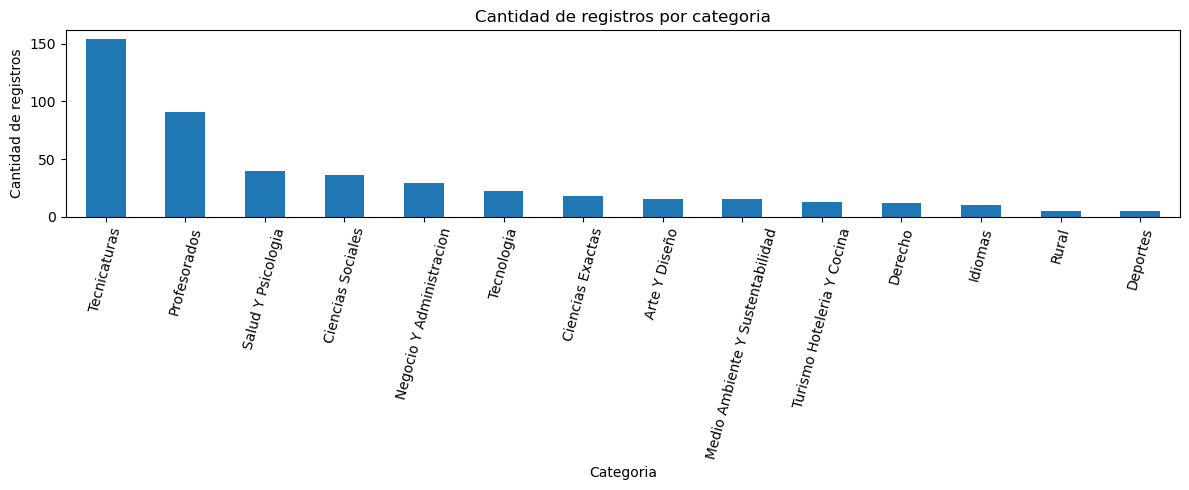

In [13]:
df["Categoria"].value_counts().plot(
    kind="bar",
    figsize=(12,5),
    rot = 75,
    grid=False
)
plt.title("Cantidad de registros por categoria")

plt.xlabel("Categoria")
plt.ylabel("Cantidad de registros")

plt.tight_layout()
plt.show()

## Grafico 2: localidades con mayor cantidad de registros

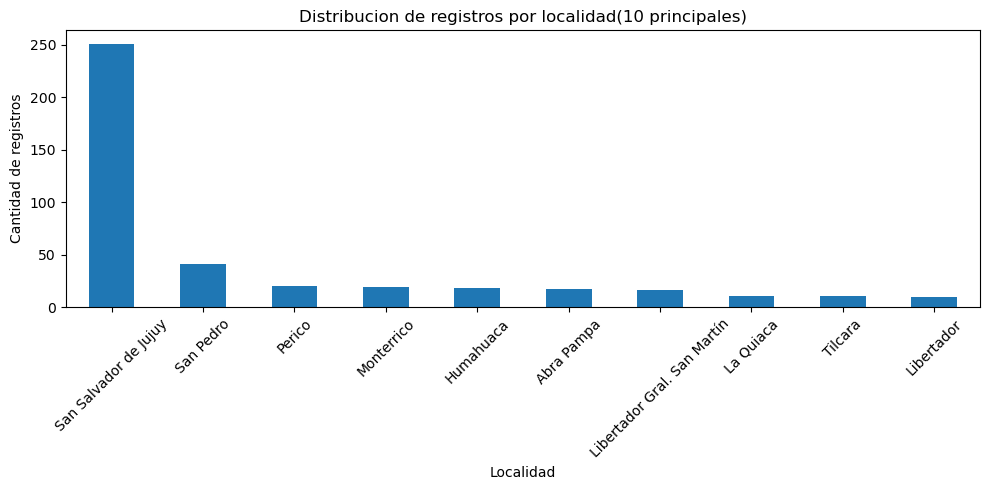

In [20]:
df["Localidad"].value_counts().head(10).plot(
    kind="bar",
    figsize=(10,5),
    rot = 45
)
plt.title("Distribucion de registros por localidad(10 principales)")

plt.xlabel("Localidad")
plt.ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

## <U>Etapa 3</U>: Analisis de registros duplicados

In [15]:
duplicados=df[df.duplicated(keep=False)]
duplicados.sort_values(
    by=["Carrera","Institucion"]
)

,Carrera,Categoria,Localidad,Institucion,Archivo_origen
458,Licenciatura en Hidrocarburos y Geociencias,Ciencias Exactas,San Salvador de Jujuy,Universidad Siglo 21,ciencias_exactas_jujuy.csv
461,Licenciatura en Hidrocarburos y Geociencias,Ciencias Exactas,San Salvador de Jujuy,Universidad Siglo 21,ciencias_exactas_jujuy.csv
427,Licenciatura en Trabajo Social – Ciclo de Comp...,Ciencias Sociales,San Salvador de Jujuy,UCASAL - Subsede Jujuy,ciencias_sociales_jujuy.csv
428,Licenciatura en Trabajo Social – Ciclo de Comp...,Ciencias Sociales,San Salvador de Jujuy,UCASAL - Subsede Jujuy,ciencias_sociales_jujuy.csv


## Duplicados Parciales

In [21]:
df[df.duplicated(subset=["Carrera","Institucion"],keep=False)].sort_values(by=["Carrera","Institucion","Localidad"])

,Carrera,Categoria,Localidad,Institucion,Archivo_origen
458,Licenciatura en Hidrocarburos y Geociencias,Ciencias Exactas,San Salvador de Jujuy,Universidad Siglo 21,ciencias_exactas_jujuy.csv
461,Licenciatura en Hidrocarburos y Geociencias,Ciencias Exactas,San Salvador de Jujuy,Universidad Siglo 21,ciencias_exactas_jujuy.csv
427,Licenciatura en Trabajo Social – Ciclo de Comp...,Ciencias Sociales,San Salvador de Jujuy,UCASAL - Subsede Jujuy,ciencias_sociales_jujuy.csv
428,Licenciatura en Trabajo Social – Ciclo de Comp...,Ciencias Sociales,San Salvador de Jujuy,UCASAL - Subsede Jujuy,ciencias_sociales_jujuy.csv
207,Profesorado de Danza con Orientación en Expres...,Arte Y Diseño,San Salvador de Jujuy,Instituto Superior de Arte,arte_y_diseño_jujuy.csv
348,Profesorado de Danza con Orientación en Expres...,Profesorados,San Salvador de Jujuy,Instituto Superior de Arte,profesorados_jujuy.csv
364,Profesorado de Educación Secundaria en Ciencia...,Derecho,Humahuaca,Instituto de Educación Superior N° 2,derecho_jujuy.csv
403,Profesorado de Educación Secundaria en Ciencia...,Ciencias Sociales,Humahuaca,Instituto de Educación Superior N° 2,ciencias_sociales_jujuy.csv
366,Profesorado de Educación Secundaria en Ciencia...,Derecho,San Salvador de Jujuy,Instituto de Educación Superior N° 5,derecho_jujuy.csv
407,Profesorado de Educación Secundaria en Ciencia...,Ciencias Sociales,San Salvador de Jujuy,Instituto de Educación Superior N° 5,ciencias_sociales_jujuy.csv


### Los primeros 4 registros son duplicados exactos, los demas, son duplicados parciales

## Investigacion de localidades

In [19]:
sorted(df["Localidad"].unique())

['Abra Pampa',
 'El Carmen',
 'Fraile Pintado',
 'Humahuaca',
 'La Mendieta',
 'La Quiaca',
 'Libertador',
 'Libertador General San Martin',
 'Libertador Gral. San Martín',
 'Maimara',
 'Monterrico',
 'Palma Sola',
 'Palpala',
 'Palpalá',
 'Palpalá - Rio Blanco',
 'Palpalá - Río Blanco',
 'Pampa Blanca',
 'Perico',
 'Rodeito',
 'San Pedro',
 'San Pedro de Jujuy',
 'San Salvado de Jujuy',
 'San Salvador de Jujuy',
 'San Salvador de Jujuy y San Pedro de Jujuy',
 'San Vicente',
 'Sede San Salvadorde Jujuy',
 'Sede Susques',
 'Susques',
 'Tilcara',
 'Tumbaya',
 'Yuto']